# Data viz / exploration — OpenF1 API

Objective: To understand what the data looks like
before building the stint optimizer.

Selected endpoints: `stints`, `laps`, `pit`, `weather`, `drivers` — only what is strictly necessary
to model tire wear. Doc: https://openf1.org/

## 1. Setup

In [15]:
import hashlib
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)
sns.set_theme(style="whitegrid", context="notebook")

BASE = "https://api.openf1.org/v1"
CACHE = Path("data/cache")
CACHE.mkdir(parents=True, exist_ok=True)


def get(endpoint, force=False, **params):
    """GET OpenF1 with a disk-based cache and a retry on 429 (rate-limited API)."""
    cle = "_".join(f"{k}={v}" for k, v in sorted(params.items()))
    path = CACHE / f"{endpoint}_{hashlib.md5(cle.encode()).hexdigest()[:10]}.parquet"
    if path.exists() and not force:
        return pd.read_parquet(path)

    for essai in range(6):
        r = requests.get(f"{BASE}/{endpoint}", params=params, timeout=60)
        if r.status_code != 429:
            break
        time.sleep(float(r.headers.get("Retry-After", 2 ** essai)))
    else:
        raise RuntimeError(f"429 persistant sur {endpoint} {params}")

    time.sleep(0.5)
    if r.status_code == 404:
        return pd.DataFrame()
    r.raise_for_status()

    df = pd.DataFrame(r.json())
    try:
        if not df.empty:
            df.to_parquet(path, index=False)
    except Exception:
        print(f"cache impossible pour {endpoint} {params}")
    return df

## 2. Loading

One request per run and per endpoint, followed by concatenation. The first run downloads
(a few minutes); subsequent runs read from the cache.

In [16]:
sessions = get("sessions", year=2025)
races = sessions.query("session_name == 'Race'")
print(f"{len(races)} races in 2025")

data = {}
for ep in ["stints", "laps", "pit", "weather", "drivers"]:
    frames = [get(ep, session_key=k) for k in races["session_key"]]
    data[ep] = pd.concat([f for f in frames if not f.empty], ignore_index=True)
    print(f"{ep:9s} {data[ep].shape}")

24 races in 2025
stints    (1318, 8)


C:\Users\natha\AppData\Local\Temp\ipykernel_15668\1805898932.py:8: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  data[ep] = pd.concat([f for f in frames if not f.empty], ignore_index=True)


laps      (26265, 16)
pit       (821, 8)
weather   (3760, 10)
drivers   (479, 12)


## 3. Columns profile

For each endpoint: type, missing values, cardinality, min/max, example.

In [17]:
def profile(df, nom=""):
    """Summary by column. The list columns (segments_sector_*) are neither
    comparable nor hashable: min/max and n_unique are None for these columns."""
    rows = []
    for col in df.columns:
        s, non_null = df[col], df[col].dropna()
        try:
            mn, mx = (non_null.min(), non_null.max()) if len(non_null) else (None, None)
        except (TypeError, ValueError):
            mn = mx = None
        try:
            nu = int(s.nunique())
        except (TypeError, ValueError):
            nu = None
        rows.append({
            "column": col, "dtype": str(s.dtype),
            "n_null": int(s.isna().sum()), "%_null": round(100 * s.isna().mean(), 1),
            "n_unique": nu, "min": mn, "max": mx,
            "example": str(non_null.iloc[0])[:55] if len(non_null) else None,
        })
    print(f"=== {nom} : {df.shape[0]} lines x {df.shape[1]} columns ===")
    return pd.DataFrame(rows)


for ep, df in data.items():
    display(profile(df, ep))

=== stints : 1318 lines x 8 columns ===


,column,dtype,n_null,%_null,n_unique,min,max,example
0,meeting_key,int64,0,0.0,24,1254,1277,1254
1,session_key,int64,0,0.0,24,9693,10033,9693
2,stint_number,int64,0,0.0,7,1,7,1
3,driver_number,int64,0,0.0,21,1,87,18
4,lap_start,float64,6,0.5,65,1.0,77.0,1.0
5,lap_end,float64,6,0.5,76,0.0,78.0,2.0
6,compound,object,0,0.0,4,HARD,SOFT,INTERMEDIATE
7,tyre_age_at_start,int64,0,0.0,36,0,54,0


=== laps : 26265 lines x 16 columns ===


,column,dtype,n_null,%_null,n_unique,min,max,example
0,meeting_key,int64,0,0.0,24.0,1254,1277,1254
1,session_key,int64,0,0.0,24.0,9693,10033,9693
2,driver_number,int64,0,0.0,21.0,1,87,81
3,lap_number,int64,0,0.0,78.0,1,78,1
4,date_start,object,19,0.1,25802.0,2025-03-16T04:18:22.973000+00:00,2025-12-07T14:29:31.521000+00:00,2025-03-16T04:18:22.973000+00:00
5,duration_sector_1,float64,124,0.5,14134.0,17.082,121.725,44.302
6,duration_sector_2,float64,71,0.3,14478.0,17.831,85.244,20.844
7,duration_sector_3,float64,75,0.3,14291.0,16.536,86.02,56.056
8,i1_speed,float64,4320,16.4,306.0,31.0,352.0,244.0
9,i2_speed,float64,956,3.6,282.0,57.0,347.0,298.0


=== pit : 821 lines x 8 columns ===


,column,dtype,n_null,%_null,n_unique,min,max,example
0,date,object,0,0.0,821,2025-03-16T04:23:12.761000+00:00,2025-12-07T14:07:26.254000+00:00,2025-03-16T04:23:12.761000+00:00
1,session_key,int64,0,0.0,24,9693,10033,9693
2,lap_number,int64,0,0.0,68,1,77,2
3,lane_duration,float64,0,0.0,731,12.8,56.757,13.3
4,stop_duration,float64,119,14.5,82,1.8,29.0,2.5
5,pit_duration,float64,0,0.0,731,12.8,56.757,13.3
6,meeting_key,int64,0,0.0,24,1254,1277,1254
7,driver_number,int64,0,0.0,21,1,87,4


=== weather : 3760 lines x 10 columns ===


,column,dtype,n_null,%_null,n_unique,min,max,example
0,date,object,0,0.0,3760,2025-03-16T03:07:30.394000+00:00,2025-12-07T14:39:07.948000+00:00,2025-03-16T03:07:30.394000+00:00
1,session_key,int64,0,0.0,24,9693,10033,9693
2,meeting_key,int64,0,0.0,24,1254,1277,1254
3,wind_direction,int64,0,0.0,359,0,359,211
4,air_temperature,float64,0,0.0,175,14.2,31.7,15.8
5,humidity,float64,0,0.0,80,14.0,93.0,91.0
6,pressure,float64,0,0.0,235,780.3,1021.9,1009.2
7,rainfall,int64,0,0.0,2,0,1,1
8,wind_speed,float64,0,0.0,60,0.0,6.9,2.6
9,track_temperature,float64,0,0.0,359,16.7,53.2,18.8


=== drivers : 479 lines x 12 columns ===


,column,dtype,n_null,%_null,n_unique,min,max,example
0,meeting_key,int64,0,0.0,24,1254,1277,1254
1,session_key,int64,0,0.0,24,9693,10033,9693
2,driver_number,int64,0,0.0,21,1,87,1
3,broadcast_name,object,0,0.0,21,A ALBON,Y TSUNODA,M VERSTAPPEN
4,full_name,object,0,0.0,21,Alexander ALBON,Yuki TSUNODA,Max VERSTAPPEN
5,name_acronym,object,0,0.0,21,ALB,VER,VER
6,team_name,object,0,0.0,10,Alpine,Williams,Red Bull Racing
7,team_colour,object,0,0.0,19,0093CC,FF8000,3671C6
8,first_name,object,0,0.0,21,Alexander,Yuki,Max
9,last_name,object,0,0.0,21,Albon,Verstappen,Verstappen


## 4. Cleans laps

We cross-reference `laps` and `stints` to determine, for each lap, the tire compound and age.
We exclude anything that doesn't reflect the actual pace: laps leaving the pits, laps entering the pits,
and laps that are > 110% of the race's fastest lap (safety car, traffic, flags).

`pace` = lap time / fastest lap of the session: comparable across different circuits.

In [18]:
laps, stints, pit = data["laps"], data["stints"], data["pit"]

laps = laps.merge(stints, on=["session_key", "driver_number"]).query(
    "lap_start <= lap_number <= lap_end"
).copy()
laps["tyre_age"] = laps["tyre_age_at_start"] + laps["lap_number"] - laps["lap_start"]

entrees_pit = set(map(tuple, pit[["session_key", "driver_number", "lap_number"]].values))
cle = list(map(tuple, laps[["session_key", "driver_number", "lap_number"]].values))
laps = laps[laps["lap_duration"].notna() & ~laps["is_pit_out_lap"]
              & ~pd.Series(cle, index=laps.index).isin(entrees_pit)]

laps["pace"] = laps["lap_duration"] / laps.groupby("session_key")["lap_duration"].transform("min")
laps = laps[laps["pace"] <= 1.10]

print(f"{len(laps)} clean laps on {len(laps)} ({len(laps) / len(laps):.0%})")
laps["compound"].value_counts()

21748 clean laps on 21748 (100%)


compound
HARD            9712
MEDIUM          9174
SOFT            2752
INTERMEDIATE     110
Name: count, dtype: int64

## 5. Visualization

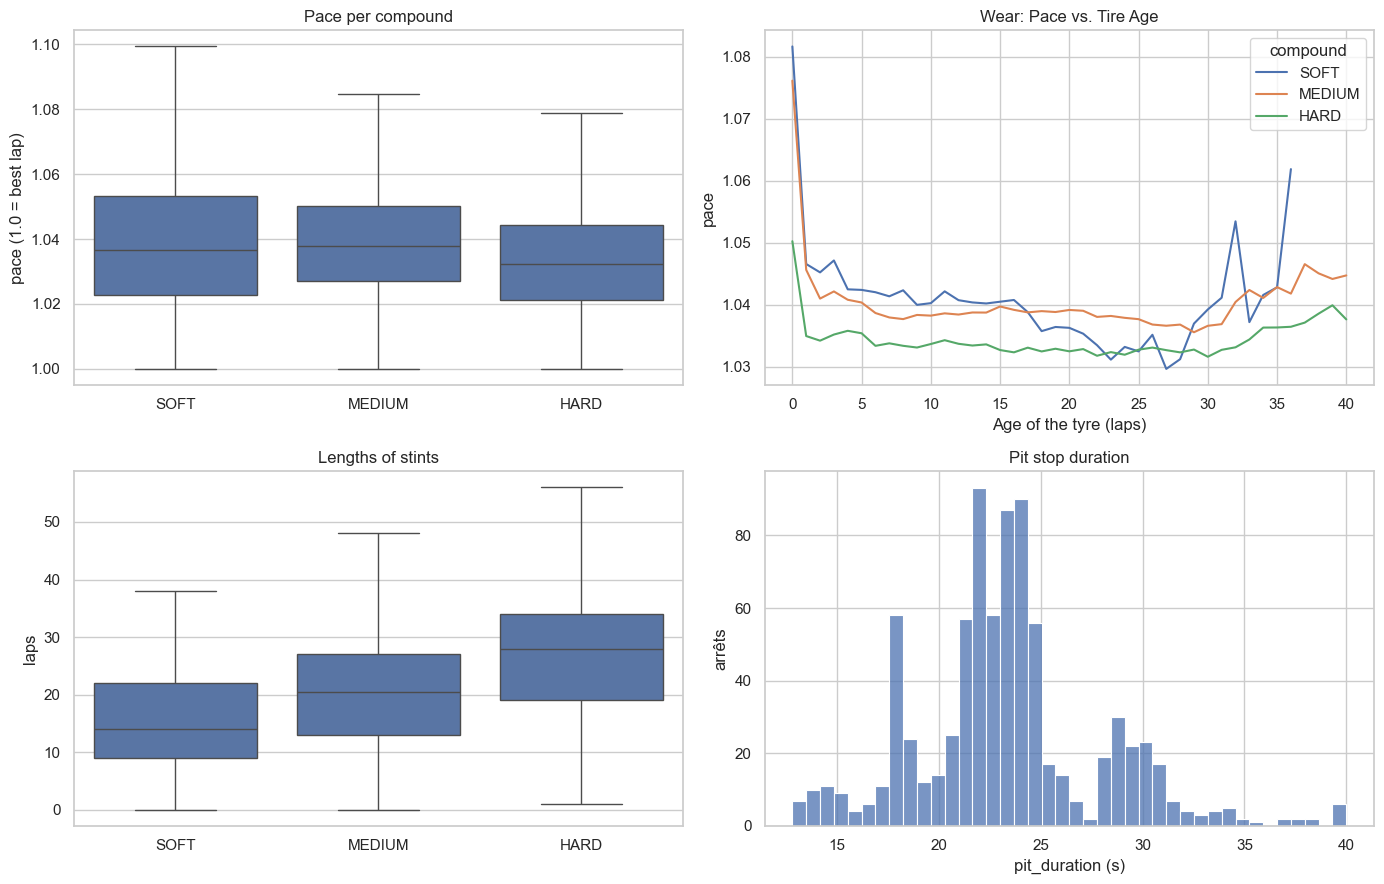

In [19]:
secs = ["SOFT", "MEDIUM", "HARD"]
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

sns.boxplot(data=laps[laps.compound.isin(secs)], x="compound", y="pace",
            order=secs, ax=axes[0, 0], showfliers=False)
axes[0, 0].set(title="Pace per compound", xlabel="", ylabel="pace (1.0 = best lap)")

sns.lineplot(data=laps[laps.compound.isin(secs) & (laps.tyre_age <= 40)],
             x="tyre_age", y="pace", hue="compound", hue_order=secs, errorbar=None, ax=axes[0, 1])
axes[0, 1].set(title="Wear: Pace vs. Tire Age", xlabel="Age of the tyre (laps)", ylabel="pace")

length = stints.assign(n_laps=stints.lap_end - stints.lap_start + 1)
sns.boxplot(data=length[length.compound.isin(secs)], x="compound", y="n_laps",
            order=secs, ax=axes[1, 0], showfliers=False)
axes[1, 0].set(title="Lengths of stints", xlabel="", ylabel="laps")

sns.histplot(pit["pit_duration"].clip(upper=40), bins=40, ax=axes[1, 1])
axes[1, 1].set(title="Pit stop duration", xlabel="pit_duration (s)", ylabel="arrêts")

fig.tight_layout()


## 6. Interruptions by Circuit (2023 → Present)

Percentage of race laps affected by a yellow or red flag, circuit by circuit.
For each race: the number of distinct laps during which race control displayed a yellow flag
(`YELLOW` + `DOUBLE YELLOW`, sector or entire track) or a red flag, divided by the race distance; circuits are aggregated across all their races since 2023.

One query per season is sufficient: `race_control` and `session_result` fit within a range
of `session_key`. Reminder: OpenF1 only accepts the **strict** operators `>` and `<`
(`session_key>=X` returns a misleading 404).

cache impossible pour session_result {'session_key>': 7762, 'session_key<': 9315}
cache impossible pour session_result {'session_key>': 9460, 'session_key<': 9674}
cache impossible pour session_result {'session_key>': 9682, 'session_key<': 10034}
cache impossible pour session_result {'session_key>': 11226, 'session_key<': 11732}
87 races eligible for 90 held since 2023


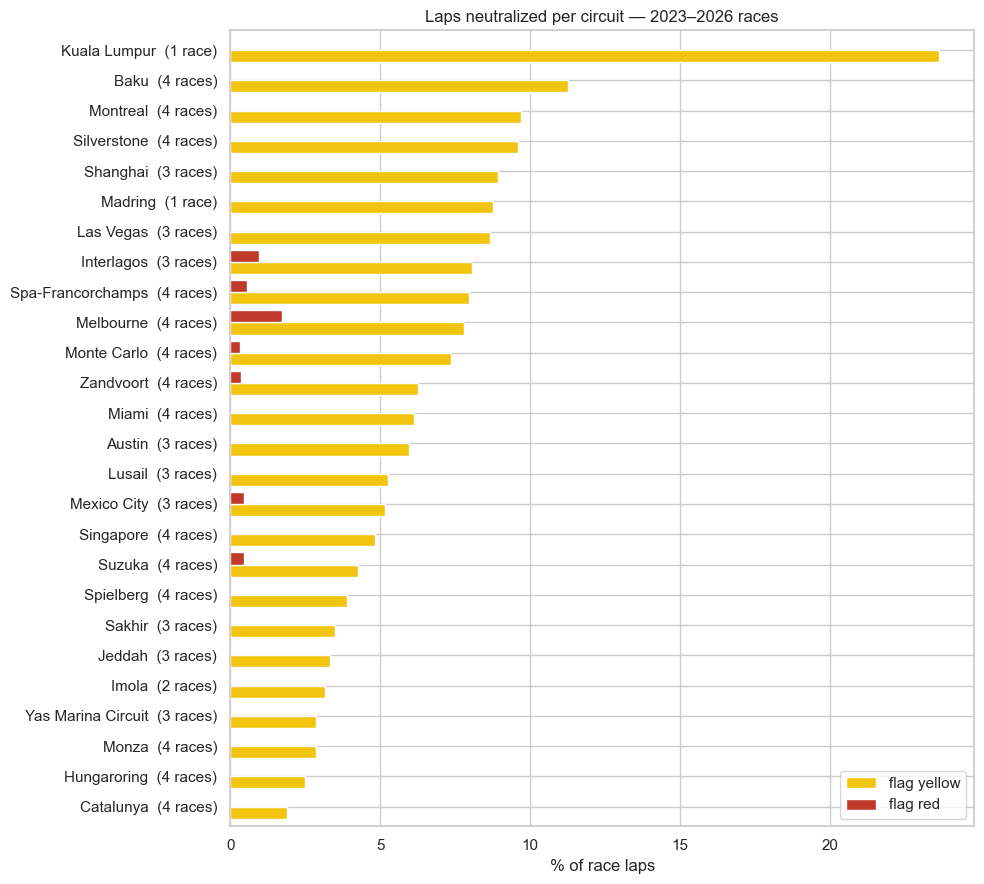

In [20]:
ses, rc, res = [], [], []
for an in [2023, 2024, 2025, 2026]:
    s = get("sessions", year=an)
    region = {"session_key>": int(s.session_key.min()) - 1, "session_key<": int(s.session_key.max()) + 1}
    ses.append(s)
    rc.append(get("race_control", **region))
    res.append(get("session_result", **region))
ses, rc, res = (pd.concat(x, ignore_index=True) for x in (ses, rc, res))

# Races Already Held: The 2026 calendar includes upcoming dates, but no details are available.
races = ses.query("session_name == 'Race'").copy()
races["date_start"] = pd.to_datetime(races["date_start"], format="ISO8601", utc=True)
races = races[races["date_start"] <= pd.Timestamp.now(tz="UTC")]

# We only keep messages sent after the start (before: pit opening, etc.).
ev = rc.assign(date=pd.to_datetime(rc["date"], format="ISO8601", utc=True)).merge(
    races[["session_key", "date_start"]], on="session_key")
ev = ev[ev["date"] >= ev["date_start"]]

def laps_under(flags):
    return ev[ev["flag"].isin(flags)].groupby("session_key")["lap_number"].nunique()

flags = races.set_index("session_key")[["circuit_short_name"]].assign(
    laps=res.groupby("session_key")["number_of_laps"].max(),   # distance = lap of the winner
    yellow=laps_under(["YELLOW", "DOUBLE YELLOW"]),
    red=laps_under(["RED"]),
).dropna(subset=["laps"]).fillna(0)

per_tracks = flags.groupby("circuit_short_name").sum()
per_tracks["yellow_%"] = 100 * per_tracks["yellow"] / per_tracks["laps"]
per_tracks["red_%"] = 100 * per_tracks["red"] / per_tracks["laps"]
per_tracks["n"] = flags.groupby("circuit_short_name").size()
print(f"{len(flags)} races eligible for {len(races)} held since 2023")

graph = per_tracks.sort_values("yellow_%").rename(
    columns={"yellow_%": "flag yellow", "red_%": "flag red"})
graph.index = [f"{c}  ({n} race{'s' * (n > 1)})" for c, n in zip(graph.index, graph["n"])]
fig, ax = plt.subplots(figsize=(10, 9))
graph[["flag yellow", "flag red"]].plot.barh(ax=ax, width=0.8, color=["#f1c40f", "#c0392b"])
ax.set(title="Laps neutralized per circuit — 2023–2026 races",
       xlabel="% of race laps", ylabel="")
ax.legend(loc="lower right")
fig.tight_layout()

## 7. Pit Stop Loss per Lap (2023 → Present)

The true cost of a pit stop is not the time spent in the pit lane, but the time lost compared
to a normal lap: `entry lap + exit lap − 2 × reference lap`. The reference is
taken from the same driver’s clean laps within ±3 laps of the pit stop, which neutralizes the
effect of fuel load, tire wear, and track conditions.

The following are excluded:

- pit stops under **safety car, VSC, or red flag**: the track is slowed down, so the pit stop costs
  much less (here, an average loss of ~86 s without neutralization versus ~25 s with it);
- **races in the rain** (rain detected by `weather`), where the out-lap depends
  primarily on the tire change;
- losses **outside the 10–45 s range**: served penalties, repairs, or botched pit stops—not standard pit stops.

C:\Users\natha\AppData\Local\Temp\ipykernel_15668\1396047307.py:4: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  every_laps = pd.concat([get("laps", session_key=k) for k in races.session_key], ignore_index=True)


1736 selected pit stops (80 dry races), average loss 22.8 s


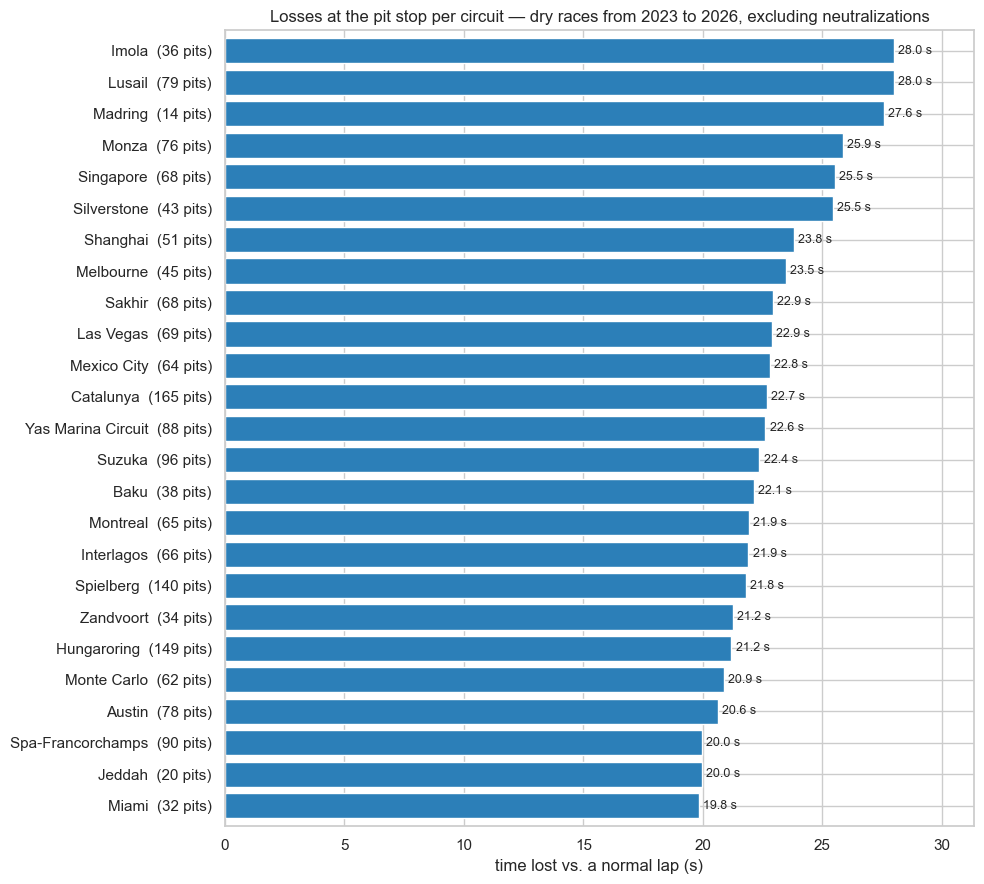

In [21]:
region = {"session_key>": int(ses.session_key.min()) - 1, "session_key<": int(ses.session_key.max()) + 1}
raw_stops = get("pit", **region)
weather = get("weather", **region)
every_laps = pd.concat([get("laps", session_key=k) for k in races.session_key], ignore_index=True)

rain = weather.groupby("session_key")["rainfall"].mean()
dry = races[~races["session_key"].isin(rain[rain > 0.1].index)]

# Neutralized laps: from the SC/VSC deployment (or the red flag) through the lap following the restart.
sc = rc[rc["message"].str.contains("SAFETY CAR DEPLOYED|SAFETY CAR IN THIS LAP|SAFETY CAR ENDING", na=False)
        | rc["flag"].eq("RED")].dropna(subset=["lap_number"]).sort_values(["session_key", "date"]).copy()
sc["start"] = sc["message"].str.contains("DEPLOYED", na=False) | sc["flag"].eq("RED")
sc["end"] = sc.groupby("session_key")["lap_number"].shift(-1).fillna(sc["lap_number"])
neutral = {(r.session_key, l) for r in sc[sc["start"]].itertuples()
           for l in range(int(r.lap_number), int(r.end) + 2)}

# Clean laps used as a reference (no pit stops or slow laps).
entry = set(zip(raw_stops.session_key, raw_stops.driver_number, raw_stops.lap_number))
keys = pd.Series(list(zip(every_laps.session_key, every_laps.driver_number, every_laps.lap_number)),
                 index=every_laps.index)
clean = every_laps[every_laps["lap_duration"].notna() & ~every_laps["is_pit_out_lap"] & ~keys.isin(every_laps)]
clean = clean[clean["lap_duration"]
                  <= 1.10 * clean.groupby("session_key")["lap_duration"].transform("min")]

# A pit stop = its entry lap (lap_number) and its exit lap (lap_number + 1).
chrono = every_laps.set_index(["session_key", "driver_number", "lap_number"])["lap_duration"]
pit = raw_stops[raw_stops["session_key"].isin(dry["session_key"])][
    ["session_key", "driver_number", "lap_number"]]
pit = pit[[(k, l) not in neutral and (k, l + 1) not in neutral
                 for k, l in zip(pit.session_key, pit.lap_number)]].reset_index(drop=True)
pit["pit"] = pit.index
pit["t_in"] = [chrono.get(i) for i in zip(pit.session_key, pit.driver_number, pit.lap_number)]
pit["t_out"] = [chrono.get(i) for i in zip(pit.session_key, pit.driver_number, pit.lap_number + 1)]

ref = (pit.merge(clean[["session_key", "driver_number", "lap_number", "lap_duration"]],
                    on=["session_key", "driver_number"], suffixes=("", "_r"))
       .query("abs(lap_number_r - lap_number) <= 3")
       .groupby("pit")["lap_duration"].agg(["median", "size"]))
pit = pit.join(ref, on="pit")
pit["loss"] = pit["t_in"] + pit["t_out"] - 2 * pit["median"]

selected = pit[(pit["size"] >= 2) & pit["loss"].between(10, 45)].assign(
    circuit=lambda d: d["session_key"].map(races.set_index("session_key")["circuit_short_name"]))
loss = selected.groupby("circuit")["loss"].agg(["mean", "count"]).sort_values("mean")
print(f"{len(selected)} selected pit stops ({len(dry)} dry races), "
      f"average loss {selected['loss'].mean():.1f} s")

fig, ax = plt.subplots(figsize=(10, 9))
loss["mean"].rename(lambda c: f"{c}  ({loss.loc[c, 'count']} pits)").plot.barh(
    ax=ax, width=0.8, color="#2c7fb8")
ax.bar_label(ax.containers[0], fmt="%.1f s", padding=3, fontsize=9)
ax.set(title="Losses at the pit stop per circuit — dry races from 2023 to 2026, excluding neutralizations",
       xlabel="time lost vs. a normal lap (s)", ylabel="", xlim=(0, loss["mean"].max() * 1.12))
fig.tight_layout()

914 laps | circuits : Austin, Baku, Catalunya, Hungaroring, Imola, Interlagos, Jeddah, Las Vegas, Lusail, Melbourne, Mexico City, Miami, Monte Carlo, Montreal, Monza, Sakhir, Shanghai, Silverstone, Singapore, Spa-Francorchamps, Spielberg, Suzuka, Yas Marina Circuit, Zandvoort


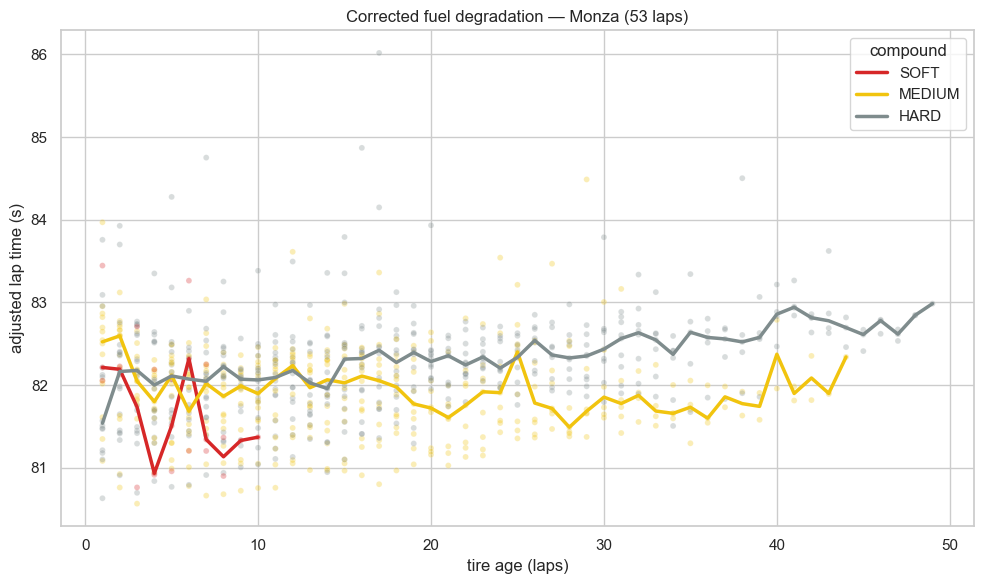

In [22]:
# 8. Fuel degradation corrected, one lap at a time.
# The tank empties by about 1.8 kg per lap, and 10 kg costs ~0.3 s: we remove this
# effect to account only for tire wear. Lap 1 excluded (standing start).
CIRCUIT = "Monza"      # Change the circuit here; the list is printed below the graph
BURN = 0.055           # seconds gained per lap of fuel burned

circuits = sessions.set_index("session_key")["circuit_short_name"]
sel = laps.assign(circuit=laps["session_key"].map(circuits)).query(
    "circuit == @CIRCUIT and lap_number > 1").copy()
distance = sel["lap_number"].max()
sel["fix"] = sel["lap_duration"] - BURN * (distance - sel["lap_number"])

compound = [g for g in ["SOFT", "MEDIUM", "HARD"] if (sel["compound"] == g).sum() > 20]
sel = sel[sel["compound"].isin(compound)]
commun = dict(data=sel, x="tyre_age", y="fix", hue="compound", hue_order=compound,
              palette={"SOFT": "#d62728", "MEDIUM": "#f1c40f", "HARD": "#7f8c8d"})

fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(**commun, ax=ax, alpha=0.3, s=18, legend=False)
sns.lineplot(**commun, ax=ax, estimator="median", errorbar=None, lw=2.5)
ax.set(title=f"Corrected fuel degradation — {CIRCUIT} ({distance} laps)",
       xlabel="tire age (laps)", ylabel="adjusted lap time (s)")
fig.tight_layout()
print(f"{len(sel)} laps | circuits : {', '.join(sorted(circuits[laps.session_key.unique()].unique()))}")

## 9. Reference Table by Circuit

The three inputs required by the optimizer, one row per circuit:

- **tire degradation** (s/lap) per tire compound;
- **pit stop loss** (s), taken from Section 7;
- **observed stint lengths** (median and maximum) per tire compound.

Tire degradation is estimated per driver and per race using a single model:
`time = constant + fuel × lap number + tire_degradation × tire age`.
The “fuel” term accounts for the lighter fuel load **and** track evolution, estimated
from the data rather than being fixed at 0.055 s/lap as in the previous cell—with
that constant, half of the circuits yielded negative tire degradation. At least
two tire compounds are required during the race; otherwise, tire age and lap number are collinear.

Only **dry races, excluding neutralized laps**, are used. An empty cell = fewer than
10 measured stints, too few for a reliable slope (this is often the case with soft tires, whose
stints are short and occur late in the race).

In [23]:
raw_relays = get("stints", **region)

base = clean[clean["session_key"].isin(dry["session_key"]) & (clean["lap_number"] > 1)]
base = base[[(k, l) not in neutral for k, l in zip(base.session_key, base.lap_number)]]
base = base.merge(raw_relays, on=["session_key", "driver_number"]).query("lap_start <= lap_number <= lap_end")
base["age"] = base["tyre_age_at_start"] + base["lap_number"] - base["lap_start"]
base["circuit"] = base["session_key"].map(races.set_index("session_key")["circuit_short_name"])

def ajuste(x):
    """Least squares: a fuel slope + a degradation slope due to gum."""
    compound = x["compound"].unique()
    if len(compound) < 2 or len(x) < 25:
        return None
    X = pd.DataFrame({"c": 1.0, "fuel": x["lap_number"]}
                     | {gom: x["age"].where(x["compound"] == gom, 0) for gom in compound})
    coef, *_ = np.linalg.lstsq(X.values, x["lap_duration"].values, rcond=None)
    return pd.Series(coef[1:], index=["fuel", *compound])

fits = (base.groupby(["circuit", "session_key", "driver_number"])
        [["lap_number", "age", "compound", "lap_duration"]].apply(ajuste).reset_index())
fits.columns = ["circuit", "session_key", "driver_number", "param", "value"]

SECS = ["SOFT", "MEDIUM", "HARD"]
n_fits = fits.pivot_table(index="circuit", columns="param", values="value", aggfunc="size")
deg = fits.pivot_table(index="circuit", columns="param", values="value", aggfunc="median")
deg = deg[SECS].where(n_fits[SECS] >= 10)

relays = base.drop_duplicates(["session_key", "driver_number", "stint_number"]).assign(
    n_laps=lambda d: d["lap_end"] - d["lap_start"] + 1)

def length(f):
    return relays.pivot_table(index="circuit", columns="compound", values="n_laps",
                              aggfunc=f).reindex(columns=SECS)

reference = pd.concat({
    "degradation (sec/lap)": deg.round(3),
    "median relay (laps)": length("median").round(0),
    "max relay (laps)": length("max"),
    "race": pd.DataFrame({
        "pit stop (s)": loss["mean"].round(1),
        "fuel (s/tour)": fits.query("param == 'fuel'").groupby("circuit")["value"].median().round(3),
    }),
}, axis=1)
reference.to_csv("data/reference_circuits.csv")
reference

degradation (sec/lap)               median relay (laps)              max relay (laps)                      race              
                                    SOFT MEDIUM   HARD                SOFT MEDIUM  HARD             SOFT MEDIUM  HARD pit stop (s) fuel (s/tour)
circuit                                                                                                                                         
Austin                             0.072  0.059  0.073                24.0   21.0  22.0             28.0   34.0  40.0         20.6        -0.070
Baku                               0.037  0.079  0.035                15.0   15.0  37.0             31.0   37.0  50.0         22.1        -0.075
Catalunya                          0.095  0.100  0.099                14.0   23.0  24.0             32.0   36.0  37.0         22.7        -0.055
Hungaroring                        0.099  0.086  0.084                14.0   20.0  28.0             34.0   45.0  55.0         21.2        -0.054
Imola                                NaN  0.046  0.046                 7.0   19.0  29.0              8.0   37.0  54.0         28.0        -0.034
Interlagos                         0.072  0.071    NaN                19.0   25.0  28.0             35.0   52.0  29.0         21.9        -0.035
Jeddah                               NaN  0.036 -0.023                14.0   17.0  33.0             16.0   41.0  49.0         20.0        -0.054
Las Vegas                            NaN  0.098  0.049                 4.0   16.0  23.0             10.0   27.0  48.0         22.9        -0.076
Lusail                               NaN  0.055  0.056                 7.0   18.0  18.0             25.0   35.0  30.0         28.0        -0.080
Madring                              NaN  0.108  0.031                11.0   14.0  39.0             23.0   20.0  55.0         27.6        -0.101
Melbourne                          0.103  0.040  0.070                10.0    9.0  25.0             25.0   38.0  48.0         23.5        -0.066
Mexico City                        0.085  0.070  0.044                24.0   28.0  37.0             37.0   44.0  49.0         22.8        -0.042
Miami                                NaN  0.048  0.038                15.0   24.0  31.0             29.0   41.0  54.0         19.8        -0.051
Monte Carlo                       -0.183  0.021  0.024                11.0   30.0  31.0             55.0   78.0  78.0         20.9        -0.016
Montreal                          -0.024  0.027  0.029                17.0   16.0  31.0             38.0   49.0  68.0         21.9        -0.045
Monza                              0.050  0.070  0.033                 3.0   19.0  25.0             24.0   50.0  51.0         25.9        -0.048
Sakhir                             0.175  0.140  0.130                13.0   19.0  20.0             25.0   31.0  30.0         22.9        -0.071
Shanghai                             NaN  0.168  0.090                 9.0   12.0  33.0             20.0   30.0  47.0         23.8        -0.075
Silverstone                        0.060  0.052  0.064                19.0   24.0  20.0             28.0   35.0  34.0         25.5        -0.063
Singapore                          0.056  0.053  0.066                22.0   25.0  34.0             61.0   60.0  49.0         25.5        -0.051
Spa-Francorchamps                  0.194  0.182  0.068                12.0   15.0  21.0             27.0   24.0  34.0         20.0        -0.077
Spielberg                          0.047  0.078  0.066                13.0   20.0  27.0             25.0   33.0  41.0         21.8        -0.030
Suzuka                             0.171  0.077  0.072                11.0   20.0  23.0             20.0   33.0  38.0         22.4        -0.075
Yas Marina Circuit                   NaN  0.106  0.053                 8.0   16.0  25.0             25.0   29.0  45.0         22.6        -0.047
Zandvoort                          0.075  0.061  0.053                19.0   23.0  38.0             25.0

## 10. Three Race Profiles

The three entries in Section 9 (tire degradation, pit stop time loss, stint lengths) reviewed
track by track, across three deliberately contrasting races:

| track | reason | details |
|---|---|---|
| **Monza** | one-stop race: virtually no tire degradation, but the most expensive pit stop on the calendar | 76 pit stops, 180 stints |
| **Catalunya** | the opposite: the highest tire wear on the calendar, and the largest sample size | 165 pit stops, 265 stints |
| **Baku** | a track prone to neutralizations — **11.3%** of laps under yellow flags since 2023, the highest on the calendar outside of Kuala Lumpur (a single race) | 38 pit stops, 154 stints |

Read by column:

- **degradation** — each point represents a clean lap; the line is the moving median by tire age;
  the label shows the adjusted slope from Section 9. Laps are expressed as
  **deviation from the median lap time of their own race**: 2023 and 2026 have neither the same cars nor
  the same track surface, and without this normalization, we would be measuring the evolution of the field rather than
  tire wear. The effect of fuel is accounted for using the estimated slope for the circuit;
- **pit stop loss** — distribution of pit stops, circuit average shown as a solid line, average across all
  circuits shown as a dashed line;
- **stint lengths** — distribution by tire compound, one point per stint.

The three columns share the same scale from one row to the next: the rows can be compared
directly. Same race layout as Section 9—dry races only, excluding neutralized laps.

> Colors: red, yellow, and gray are the F1 tire codes. Yellow remains clearly visible against a
> white background, so each curve also has its own label and each box has its median value:
> identification is never based on color alone.

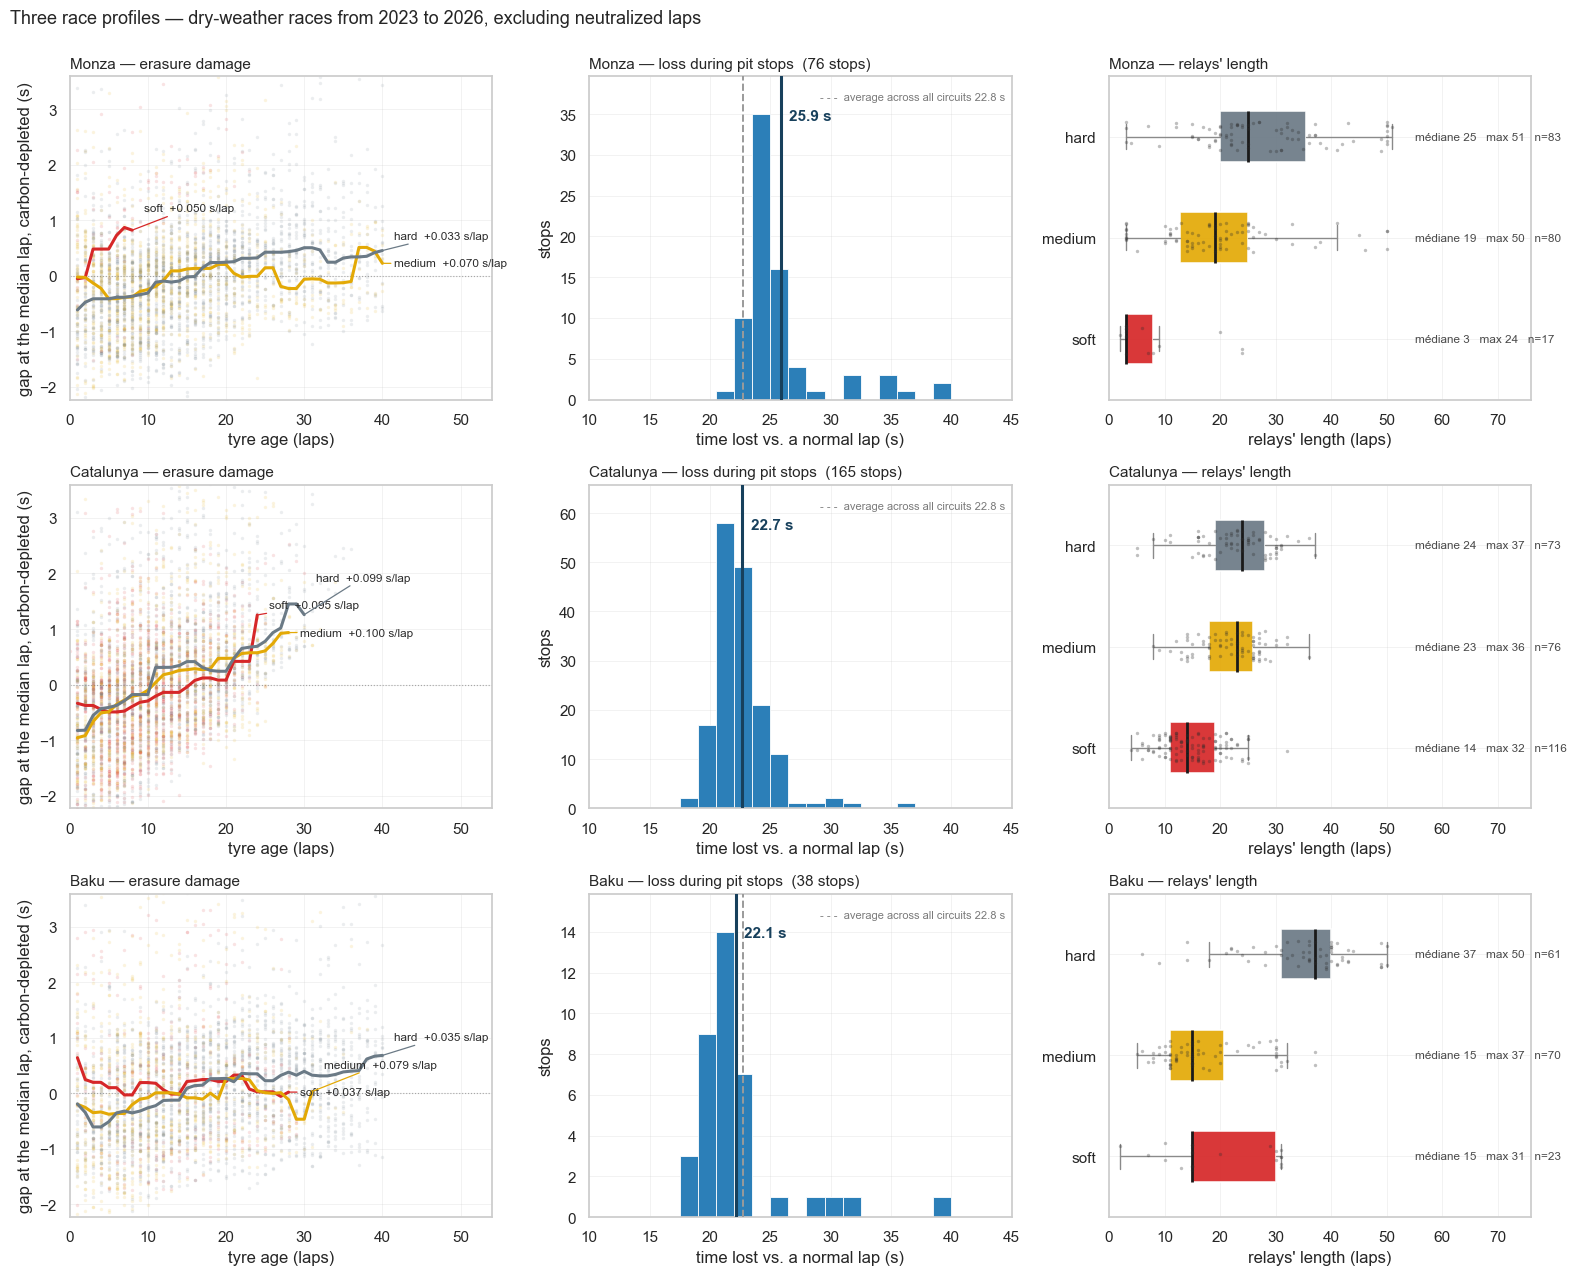

In [26]:
THREE = ["Monza", "Catalunya", "Baku"]
COMPOUND = {"SOFT": "#d62728", "MEDIUM": "#e3a906", "HARD": "#6b7a86"}
MAX_AGE = 40

# times adjusted to the median lap time of THEIR race (performance levels vary
# from one season to the next), then adjusted for the track's gradient.
fuel = fits.query("param == 'fuel'").groupby("circuit")["value"].median()
cloud = base[base["circuit"].isin(THREE) & (base["age"] <= MAX_AGE)].copy()
per_race = cloud.groupby("session_key")
cloud["gap"] = (cloud["lap_duration"] - per_race["lap_duration"].transform("median")
                  - cloud["circuit"].map(fuel)
                  * (cloud["lap_number"] - per_race["lap_number"].transform("median")))

ylim = tuple(np.percentile(cloud["gap"], [2, 98]) * 1.15)
max_relays = relays[relays["circuit"].isin(THREE)]["n_laps"].max()
global_loss = selected["loss"].mean()


def no_overlap(ys, mini):
    """Spaces out labels that are too close together vertically, while maintaining their order."""
    order = np.argsort(ys)
    ratings = np.array(ys, dtype=float)[order]
    for i in range(1, len(ratings)):
        ratings[i] = max(ratings[i], ratings[i - 1] + mini)
    output = np.empty_like(ratings)
    output[order] = ratings
    return output


fig, axes = plt.subplots(3, 3, figsize=(16, 13))
alea = np.random.default_rng(0)

for line, circuit in enumerate(THREE):
    laps_c = cloud[cloud["circuit"] == circuit]

    # --- degradation: lap cloud + moving median by tire -------------------
    ax = axes[line, 0]
    fins = []
    for gom in [g for g in SECS if (laps_c["compound"] == g).sum() > 50]:
        pts = laps_c[laps_c["compound"] == gom]
        ax.scatter(pts["age"], pts["gap"], s=6, alpha=0.13, color=COMPOUND[gom], lw=0, zorder=1)
        med = pts.groupby("age")["gap"].agg(["median", "size"])
        med = med[med["size"] >= 5]["median"].rolling(3, center=True, min_periods=1).median()
        ax.plot(med.index, med.values, color=COMPOUND[gom], lw=2.2, zorder=3, solid_capstyle="round")
        slope = deg.loc[circuit, gom]
        fins.append((med.values[-1], med.index[-1], COMPOUND[gom],
                     f"{gom.lower()}  {slope:+.3f} s/lap" if pd.notna(slope) else gom.lower()))
    for y, (y0, x0, color, text) in zip(
            no_overlap([f[0] for f in fins], 0.085 * (ylim[1] - ylim[0])), fins):
        ax.annotate(text, (x0, y0), xytext=(x0 + 1.5, y), fontsize=8.5, va="center",
                    color="#2b2b2b", zorder=4,
                    arrowprops=dict(arrowstyle="-", color=color, lw=0.9, shrinkA=0, shrinkB=1))
    ax.axhline(0, color="#9a9a9a", lw=0.8, ls=":", zorder=0)
    ax.set(xlim=(0, MAX_AGE + 14), ylim=ylim, xlabel="tyre age (laps)",
           ylabel="gap at the median lap, carbon-depleted (s)")
    ax.set_title(f"{circuit} — erasure damage", loc="left", fontsize=11)

    # --- loss au stand ---------------------------------------------------------------
    ax = axes[line, 1]
    p = selected.loc[selected["circuit"] == circuit, "loss"]
    ax.hist(p, bins=np.arange(10, 46, 1.5), color="#2c7fb8", edgecolor="white", lw=0.6, zorder=2)
    top = ax.get_ylim()[1]
    ax.axvline(global_loss, color="#9a9a9a", lw=1.4, ls="--", zorder=3)
    ax.axvline(p.mean(), color="#17405c", lw=2.2, zorder=4)
    ax.annotate(f"{p.mean():.1f} s", (p.mean(), top * 0.97), xytext=(6, 0),
                textcoords="offset points", fontsize=11, fontweight="bold",
                color="#17405c", va="top", zorder=5)
    ax.annotate(f"- - -  average across all circuits {global_loss:.1f} s", (0.985, 0.95),
                xycoords="axes fraction", ha="right", va="top", fontsize=8, color="#7a7a7a")
    ax.set(xlim=(10, 45), ylim=(0, top * 1.08),
           xlabel="time lost vs. a normal lap (s)", ylabel="stops")
    ax.set_title(f"{circuit} — loss during pit stops  ({len(p)} stops)", loc="left", fontsize=11)

    # --- relays' length ----------------------------------------------------------
    ax = axes[line, 2]
    r = relays[relays["circuit"] == circuit]
    present = [g for g in SECS if (r["compound"] == g).sum() >= 5]
    for i, gom in enumerate(present):
        n = r.loc[r["compound"] == gom, "n_laps"]
        ax.boxplot([n], positions=[i], vert=False, widths=0.5, showfliers=False,
                   patch_artist=True, medianprops=dict(color="#1a1a1a", lw=2),
                   boxprops=dict(facecolor=COMPOUND[gom], edgecolor="white", lw=1.2, alpha=0.92),
                   whiskerprops=dict(color="#8a8a8a"), capprops=dict(color="#8a8a8a"))
        ax.scatter(n, i + alea.uniform(-0.15, 0.15, len(n)), s=6, color="#2b2b2b",
                   alpha=0.3, lw=0, zorder=3)
        ax.annotate(f"médiane {n.median():.0f}   max {n.max():.0f}   n={len(n)}",
                    (max_relays + 4, i), ha="left", va="center", fontsize=8.5, color="#4a4a4a")
    ax.set(yticks=range(len(present)), yticklabels=[g.lower() for g in present],
           xlim=(0, max_relays + 25), ylim=(-0.6, len(present) - 0.4),
           xlabel="relays' length (laps)")
    ax.set_title(f"{circuit} — relays' length", loc="left", fontsize=11)

for ax in axes.flat:
    ax.grid(alpha=0.3, lw=0.6)
    ax.set_axisbelow(True)

fig.suptitle("Three race profiles — dry-weather races from 2023 to 2026, excluding neutralized laps",
             fontsize=13, x=0.006, ha="left")
fig.tight_layout(rect=(0, 0, 1, 0.985))

## Findings from the Analysis (Phase 1)

**Scope**: Dry races from 2023 to 2026, excluding neutralized laps. Three circuits compared: Monza, Catalunya, and Baku.

### Findings
- **The circuit has the greatest impact on lap times**: approximately +0.09 s/lap at Catalunya versus +0.04 to +0.05 at Monza and Baku. The circuit will be a mandatory variable in the model.
- **Time lost during pit stops is consistent across circuits**: Monza 26.0 s (76 stops), Catalunya 22.7 s (165), Baku 22.3 s (38), compared to an average of 22.9 s. A few slow pit stops can take up to 40 s.
- **The strategies employed are clear** (median stint lengths):
  - Baku: medium for 15 laps, then hard for 37.
  - Catalunya: soft for 14 laps, medium for 23, hard for 24—essentially two pit stops.
  - Monza: medium for 19 laps, hard for 25.
- **The noise is on the same order of magnitude as the tire effect**: the scatter plot spans approximately ±1 s, which is the cumulative effect of an entire hard-tire stint. Driver, team, and traffic variables will need to be accounted for.

### To be verified before modeling
- [ ] **Slopes by tire compound**: These vary by a factor of 2 depending on the fuel correction (Monza medium: flat, then +0.05). Determine and document the method.
- [ ] **Separate 2026** from other seasons: at Catalunya, the three tire compounds have the same slope (+0.085 to +0.091), which is suspicious.
- [ ] **Uncertainty intervals** for each slope, by resampling by stint.
- [ ] **Significance threshold**: no slope below approximately 30 stints. The soft compound at Monza (17 stints, median of 3 laps) is not usable.

### Decisions for the future
1. A model per circuit, or circuit-variable, with a linear benchmark (tire age + fuel + driver/team) to beat.
2. Pit stop loss: median per circuit, plus slow pit stops treated as a distribution tail.
3. Account for a lower pit stop loss **under the safety car**: pit stops during neutralization periods are excluded here, and this is where many strategies come into play.
4. Time breakdown: learning phase in 2023–2024, validation in 2025, 2026 handled separately.
5. The simulator only offers stints similar to those already observed on the track.

### Final Consistency Test
Hypothesis to test: the simulator should predict a single pit stop at Monza and Baku, and approximately two at Catalunya.